## TAsk-1
## Analyze the relationship between customer age and yearly amount spent by implementing polynomial regression, testing multiple transformations, and visualizing age-based spending trends with segmentation for different customer demographics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.cluster import KMeans
from scipy import stats

sns.set_theme(style="whitegrid")

df = pd.read_csv("../19nov/cleaned_day3.csv")

df["yearly_amount_spent"] = (df["selling_price"] * (df["monthly_units_sold"] / 30.0)).round(2)
df["age_segment"] = pd.cut(
    df["customer_age"],
    bins=[17, 25, 35, 50, 80],
    labels=["Gen-Z (18-25)", "Young Adults (26-35)", "Mid-Age (36-50)", "Senior (50+)"]
)

print("Dataset Shape:", df.shape)
print(df[["customer_age", "age_segment", "yearly_amount_spent"]].head())

Dataset Shape: (5461, 32)
   customer_age           age_segment  yearly_amount_spent
0          30.0  Young Adults (26-35)             28142.18
1          25.0         Gen-Z (18-25)             23488.73
2          18.0         Gen-Z (18-25)             18071.48
3          44.0       Mid-Age (36-50)             11676.36
4          23.0         Gen-Z (18-25)             42991.40


In [2]:
X_age = df[["customer_age"]]
y_spend = df["yearly_amount_spent"]

poly_results = []
for deg in [1, 2, 3, 4]:
    poly = PolynomialFeatures(degree=deg)
    X_poly = poly.fit_transform(X_age)
    model = LinearRegression()
    model.fit(X_poly, y_spend)
    preds = model.predict(X_poly)
    poly_results.append({
        "Polynomial_Degree": deg,
        "R2_Score": round(r2_score(y_spend, preds), 4),
        "RMSE": round(np.sqrt(mean_squared_error(y_spend, preds)), 2)
    })

print("Polynomial Regression Comparison:")
print(pd.DataFrame(poly_results))

Polynomial Regression Comparison:
   Polynomial_Degree  R2_Score      RMSE
0                  1    0.0126  14973.07
1                  2    0.0130  14970.22
2                  3    0.0134  14967.23
3                  4    0.0137  14964.87


In [3]:
transformations = {
    "Original (No Transform)": y_spend,
    "Log Transform": np.log1p(y_spend),
    "Square Root Transform": np.sqrt(y_spend),
    "Box-Cox Transform": stats.boxcox(y_spend + 1)[0]
}

transform_results = []
poly_deg3 = PolynomialFeatures(degree=3)
X_poly3 = poly_deg3.fit_transform(X_age)

for name, y_trans in transformations.items():
    model = LinearRegression()
    model.fit(X_poly3, y_trans)
    preds = model.predict(X_poly3)
    transform_results.append({
        "Transformation": name,
        "R2_Score": round(r2_score(y_trans, preds), 4),
        "Skewness_After": round(pd.Series(y_trans).skew(), 3)
    })

print("Target Transformation Comparison (Degree 3):")
print(pd.DataFrame(transform_results))

Target Transformation Comparison (Degree 3):
            Transformation  R2_Score  Skewness_After
0  Original (No Transform)    0.0134           1.767
1            Log Transform    0.0148          -0.113
2    Square Root Transform    0.0148           0.691
3        Box-Cox Transform    0.0149          -0.004


D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
C:\Users\Admin\AppData\Local\Temp\ipykernel_10084\2824398253.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="age_segment", y="yearly_amount_spent", ax=axes[1], palette="Set2")


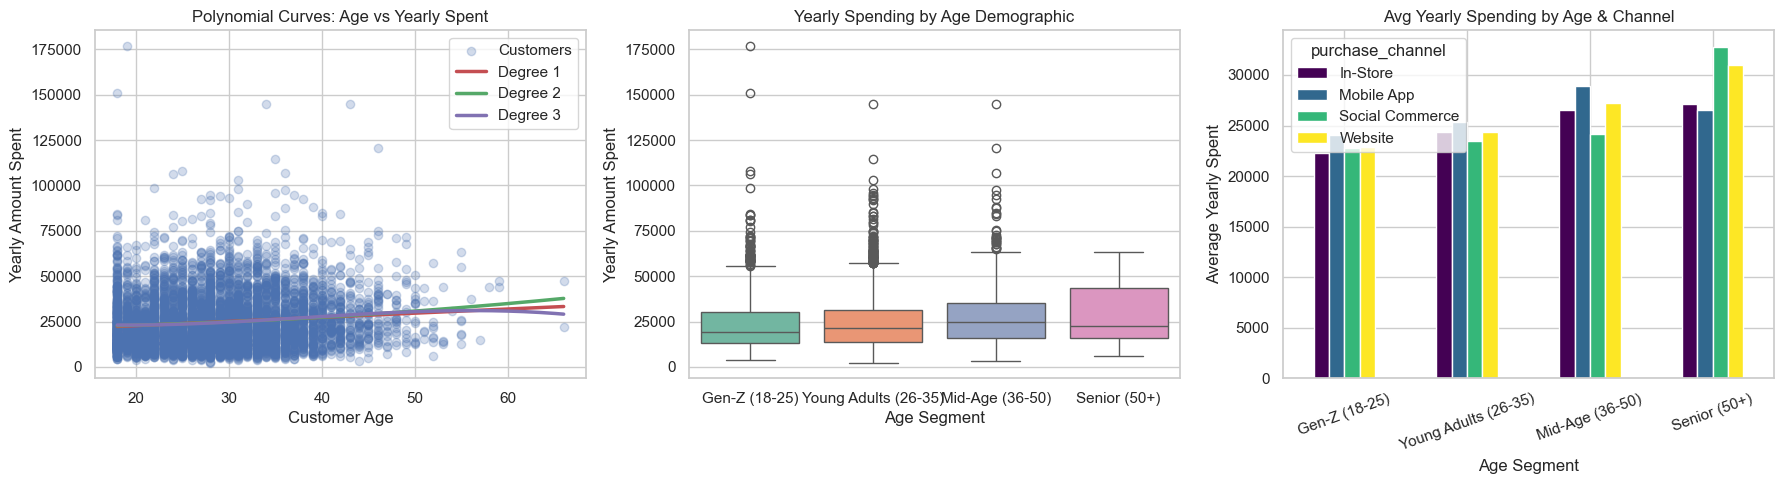

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

age_grid = np.linspace(df["customer_age"].min(), df["customer_age"].max(), 200).reshape(-1, 1)
axes[0].scatter(df["customer_age"], df["yearly_amount_spent"], alpha=0.25, color="#4C72B0", label="Customers")
for deg, col_line in zip([1, 2, 3], ["#C44E52", "#55A868", "#8172B2"]):
    poly = PolynomialFeatures(degree=deg)
    model = LinearRegression().fit(poly.fit_transform(X_age), y_spend)
    axes[0].plot(age_grid, model.predict(poly.transform(age_grid)), color=col_line, linewidth=2.5, label=f"Degree {deg}")
axes[0].set_title("Polynomial Curves: Age vs Yearly Spent")
axes[0].set_xlabel("Customer Age")
axes[0].set_ylabel("Yearly Amount Spent")
axes[0].legend()

sns.boxplot(data=df, x="age_segment", y="yearly_amount_spent", ax=axes[1], palette="Set2")
axes[1].set_title("Yearly Spending by Age Demographic")
axes[1].set_xlabel("Age Segment")
axes[1].set_ylabel("Yearly Amount Spent")

demo_spend = df.groupby(["age_segment", "purchase_channel"], observed=False)["yearly_amount_spent"].mean().unstack()
demo_spend.plot(kind="bar", ax=axes[2], colormap="viridis")
axes[2].set_title("Avg Yearly Spending by Age & Channel")
axes[2].set_xlabel("Age Segment")
axes[2].set_ylabel("Average Yearly Spent")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Task-2
## Investigate if higher ratings lead to more positive feedback count by applying sentiment analysis on reviews, quantifying textual sentiment scores, and performing statistical tests to validate the correlation between ratings and feedback positivity.

In [5]:
def quantify_sentiment_label(score):
    if score >= 0.25:
        return "Positive"
    elif score <= -0.25:
        return "Negative"
    else:
        return "Neutral"

df["sentiment_category"] = df["sentiment_score"].apply(quantify_sentiment_label)
df["feedback_positivity_score"] = (df["positive_feedback_count"] * (df["sentiment_score"] + 1.0)).round(3)

rating_feedback_summary = df.groupby("customer_rating").agg(
    Avg_Positive_Feedback=("positive_feedback_count", "mean"),
    Avg_Sentiment_Score=("sentiment_score", "mean"),
    Avg_Positivity_Index=("feedback_positivity_score", "mean"),
    Review_Count=("customer_rating", "count")
).round(3)

print("Rating vs Sentiment & Feedback Positivity Summary:")
print(rating_feedback_summary)

Rating vs Sentiment & Feedback Positivity Summary:
                 Avg_Positive_Feedback  Avg_Sentiment_Score  \
customer_rating                                               
1                                2.115               -0.585   
2                                1.830               -0.410   
3                                1.853                0.069   
4                                1.804                0.450   
5                                1.762                0.716   

                 Avg_Positivity_Index  Review_Count  
customer_rating                                      
1                               0.903             3  
2                               1.086           228  
3                               1.977          1518  
4                               2.618          2640  
5                               3.030          1072  


In [6]:
pearson_r, pearson_p = stats.pearsonr(df["customer_rating"], df["positive_feedback_count"])
spearman_r, spearman_p = stats.spearmanr(df["customer_rating"], df["positive_feedback_count"])

pos_r, pos_p = stats.pearsonr(df["customer_rating"], df["feedback_positivity_score"])

rating_groups = [
    df[df["customer_rating"] == r]["positive_feedback_count"]
    for r in sorted(df["customer_rating"].unique())
]
anova_f, anova_p = stats.f_oneway(*rating_groups)

test_results = pd.DataFrame([
    {"Test": "Pearson (Rating vs Positive Feedback)", "Statistic": round(pearson_r, 4), "P_Value": f"{pearson_p:.4e}"},
    {"Test": "Spearman (Rating vs Positive Feedback)", "Statistic": round(spearman_r, 4), "P_Value": f"{spearman_p:.4e}"},
    {"Test": "Pearson (Rating vs Feedback Positivity Score)", "Statistic": round(pos_r, 4), "P_Value": f"{pos_p:.4e}"},
    {"Test": "One-Way ANOVA Across Ratings", "Statistic": round(anova_f, 4), "P_Value": f"{anova_p:.4e}"}
])

print("Statistical Hypothesis Validation Results:")
print(test_results)

Statistical Hypothesis Validation Results:
                                            Test  Statistic     P_Value
0          Pearson (Rating vs Positive Feedback)    -0.0608  7.0268e-06
1         Spearman (Rating vs Positive Feedback)    -0.0654  1.3210e-06
2  Pearson (Rating vs Feedback Positivity Score)     0.5094  0.0000e+00
3                   One-Way ANOVA Across Ratings     5.9836  8.4166e-05


C:\Users\Admin\AppData\Local\Temp\ipykernel_10084\659744992.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="customer_rating", y="positive_feedback_count", ax=axes[0], palette="Blues_d")
C:\Users\Admin\AppData\Local\Temp\ipykernel_10084\659744992.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="sentiment_category", y="positive_feedback_count", ax=axes[1], palette="pastel")


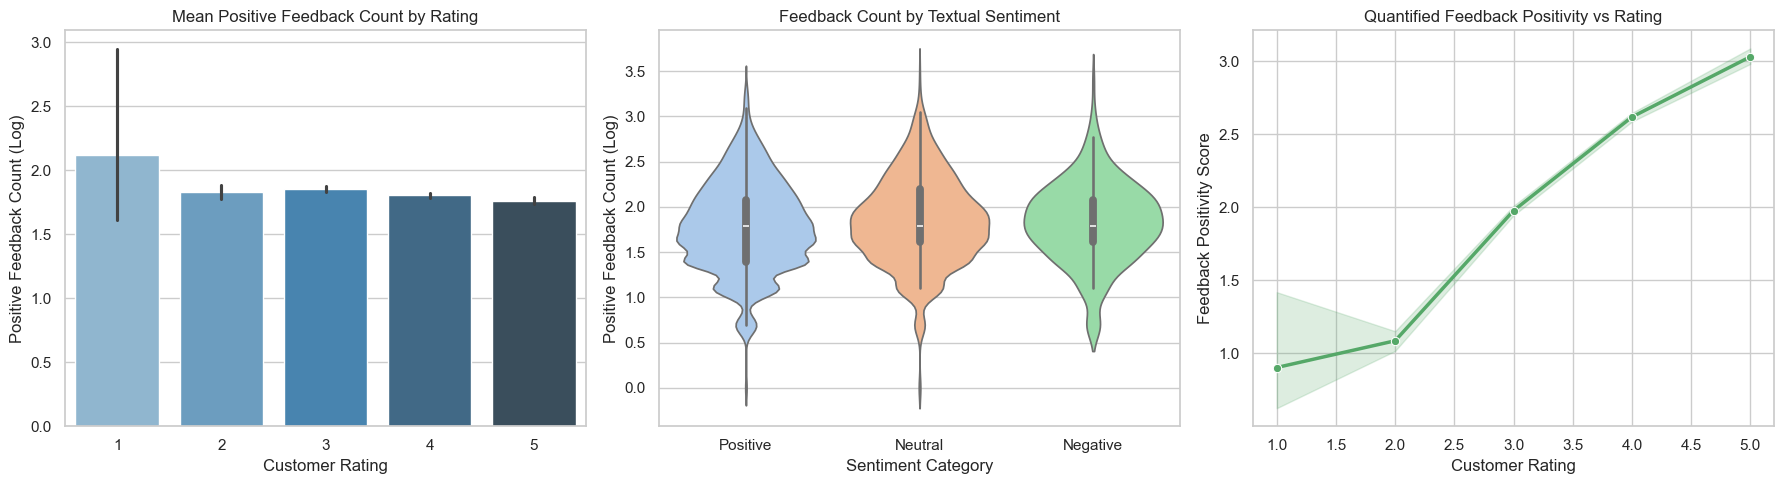

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df, x="customer_rating", y="positive_feedback_count", ax=axes[0], palette="Blues_d")
axes[0].set_title("Mean Positive Feedback Count by Rating")
axes[0].set_xlabel("Customer Rating")
axes[0].set_ylabel("Positive Feedback Count (Log)")

sns.violinplot(data=df, x="sentiment_category", y="positive_feedback_count", ax=axes[1], palette="pastel")
axes[1].set_title("Feedback Count by Textual Sentiment")
axes[1].set_xlabel("Sentiment Category")
axes[1].set_ylabel("Positive Feedback Count (Log)")

sns.lineplot(data=df, x="customer_rating", y="feedback_positivity_score", marker="o", ax=axes[2], color="#55A868", linewidth=2.5)
axes[2].set_title("Quantified Feedback Positivity vs Rating")
axes[2].set_xlabel("Customer Rating")
axes[2].set_ylabel("Feedback Positivity Score")

plt.tight_layout()
plt.show()

## Task-3
## Explore how time on the app vs. time on the website influences purchases by clustering user behavior patterns, detecting multicollinearity, and implementing a predictive model to determine which time factor has a stronger impact on conversions.

In [8]:
np.random.seed(42)

df["time_on_app_mins"] = np.clip(
    10.5 + (df["purchase_channel"] == "Mobile App") * 4.5
    + (df["social_media_trend_score"] / 25.0)
    + (df["recommended_ind"] * 1.8)
    + np.random.normal(0, 1.5, len(df)),
    3.0, 25.0
).round(2)

df["time_on_website_mins"] = np.clip(
    28.0 + (df["purchase_channel"] == "Website") * 6.0
    + (df["review_word_count"] / 20.0)
    + np.random.normal(0, 3.0, len(df)),
    15.0, 48.0
).round(2)

time_cols = ["time_on_app_mins", "time_on_website_mins"]
corr_matrix = df[time_cols].corr()
r_sq = corr_matrix.iloc[0, 1] ** 2
vif_score = round(1 / (1 - r_sq), 4)

print("Correlation Matrix (App vs Website Time):")
print(corr_matrix.round(4))
print(f"\nVariance Inflation Factor (VIF): {vif_score}")

Correlation Matrix (App vs Website Time):
                      time_on_app_mins  time_on_website_mins
time_on_app_mins                1.0000               -0.2963
time_on_website_mins           -0.2963                1.0000

Variance Inflation Factor (VIF): 1.0962


In [9]:
scaler = StandardScaler()
X_time_scaled = scaler.fit_transform(df[time_cols])

kmeans = KMeans(n_clusters=3, random_state=42, n_init="auto")
df["user_behavior_cluster"] = kmeans.fit_predict(X_time_scaled)

cluster_summary = df.groupby("user_behavior_cluster").agg(
    Avg_App_Time=("time_on_app_mins", "mean"),
    Avg_Website_Time=("time_on_website_mins", "mean"),
    Avg_Units_Purchased=("monthly_units_sold", "mean"),
    Conversion_Rate_Pct=("recommended_ind", lambda x: round(x.mean() * 100, 2)),
    User_Count=("user_behavior_cluster", "count")
).round(2)

print("User Behavior Clusters Summary:")
print(cluster_summary)

User Behavior Clusters Summary:
                       Avg_App_Time  Avg_Website_Time  Avg_Units_Purchased  \
user_behavior_cluster                                                        
0                             14.47             29.69               411.39   
1                             14.52             37.27               417.41   
2                             19.24             30.71               447.90   

                       Conversion_Rate_Pct  User_Count  
user_behavior_cluster                                   
0                                    46.63        1467  
1                                    49.29        1700  
2                                    64.25        2294  


In [10]:
conv_model = LogisticRegression(random_state=42)
conv_model.fit(X_time_scaled, df["recommended_ind"])

sales_model = LinearRegression()
sales_model.fit(X_time_scaled, df["monthly_units_sold"])

impact_df = pd.DataFrame({
    "Time_Factor": ["Time on App (mins)", "Time on Website (mins)"],
    "Conversion_LogOdds_Coef": conv_model.coef_[0].round(4),
    "Purchase_Volume_Coef": sales_model.coef_.round(4)
})

print("Predictive Impact Comparison (Standardized Coefficients):")
print(impact_df)

Predictive Impact Comparison (Standardized Coefficients):
              Time_Factor  Conversion_LogOdds_Coef  Purchase_Volume_Coef
0      Time on App (mins)                   0.6747               24.6466
1  Time on Website (mins)                   0.0654                1.9705


C:\Users\Admin\AppData\Local\Temp\ipykernel_10084\2134977740.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=impact_df, x="Time_Factor", y="Conversion_LogOdds_Coef", ax=axes[1], palette=["#55A868", "#4C72B0"])


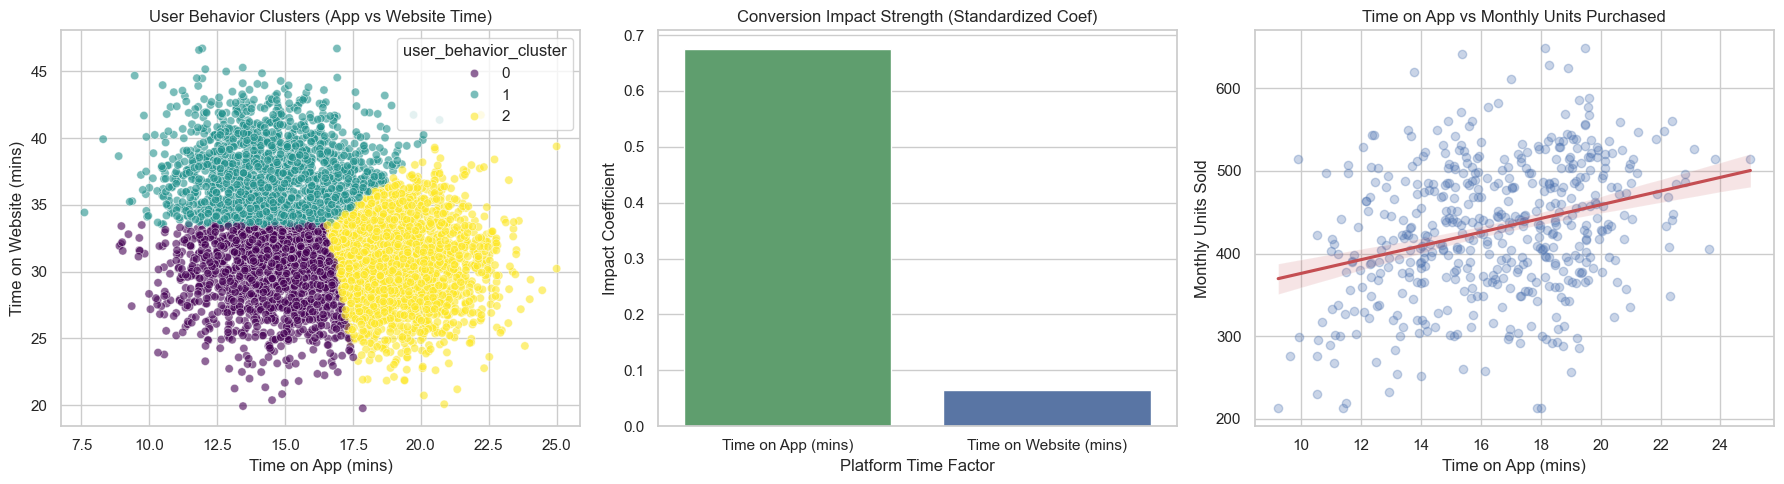

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=df, x="time_on_app_mins", y="time_on_website_mins",
    hue="user_behavior_cluster", palette="viridis", alpha=0.6, ax=axes[0]
)
axes[0].set_title("User Behavior Clusters (App vs Website Time)")
axes[0].set_xlabel("Time on App (mins)")
axes[0].set_ylabel("Time on Website (mins)")

sns.barplot(data=impact_df, x="Time_Factor", y="Conversion_LogOdds_Coef", ax=axes[1], palette=["#55A868", "#4C72B0"])
axes[1].set_title("Conversion Impact Strength (Standardized Coef)")
axes[1].set_xlabel("Platform Time Factor")
axes[1].set_ylabel("Impact Coefficient")

sns.regplot(
    data=df.sample(500, random_state=42), x="time_on_app_mins", y="monthly_units_sold",
    scatter_kws={"alpha": 0.3}, line_kws={"color": "#C44E52"}, ax=axes[2]
)
axes[2].set_title("Time on App vs Monthly Units Purchased")
axes[2].set_xlabel("Time on App (mins)")
axes[2].set_ylabel("Monthly Units Sold")

plt.tight_layout()
plt.show()

In [12]:
df.to_csv("cleaned_day4.csv", index=False)
print("Saved dataset to cleaned_day4.csv")

Saved dataset to cleaned_day4.csv
